# ETL and EDA pipeline
This workbook combines the workflow to extract, inspect, validate, transform and load data from the K-pro database API to a MySQL database. 

In [1]:
# Import packages
import os
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from pathlib import Path
from mysql import connector
from dotenv import load_dotenv
from Protein_Sequence_Based_Prediction_of_Folding_Kinetics import (
    get_endpoint,
    save_raw_response,
    prepare_columns,
    validate, 
    clean, 
    quality_assurance, 
    transform, 
    load_data,
    add_sequences
    )


### Setup variables

In [ ]:
# Establish connect to .env variables
load_dotenv()

# Load variables
API_URL = os.getenv('API_URL')
MYSQL_HOST = os.getenv('MYSQL_HOST')
MYSQL_PORT = os.getenv('MYSQL_PORT')
MYSQL_USER = os.getenv('MYSQL_USER')
MYSQL_PASSWORD =os.getenv('MYSQL_PASSWORD')
MYSQL_DATABASE = os.getenv('MYSQL_DATABASE')

RAW_DIR = Path("data/raw")

# Save column data
PROBLEM_COLUMNS = ['PFAM', 'CATH', 'BACKGROUND_MUT_PDB', 'BACKGROUND_MUT_UNIPROT']
# Expected columns of K-pro website
EXP_COLUMNS = ['PROTEIN', 'SOURCE', 'LENGTH', 'UniProt', 'PFAM',
               'CATH', 'EC_NUMBER', 'PDB_wild', 'MUTATED_CHAIN',
               'MUTATION_UNIPROT', 'MUTATION_PDB', 'SEC_STR',
               'RSA', 'T', 'pH', 'BUFFER_NAME', 'BUFFER_CONC',
               'ION_NAME', 'ADDITIVES', 'MEASURE_KIN', 'METHOD_KIN',
               'ln(kf)_H2O', 'dln(kf)_H2O', 'ln(ku)_H2O', 'dln(ku)_H2O',
               'ln(kf)_DEN', 'dln(kf)_DEN', 'ln(ku)_DEN', 'dln(ku)_DEN',
               'dGKIN_H2O', 'ddGKIN_H2O', 'mf', 'mu', 'CM_KIN', 'beta-T',
               'PhiF_H2O', 'STATE', 'REVERSIBILITY', 'AUTHOR_KIN',
               'REFERENCE_KIN', 'YEAR_KIN', 'PMID_KIN', 'REVIEW_DATE',
               'BACKGROUND_MUT_UNIPROT', 'BACKGROUND_MUT_PDB'
               ]

In [3]:
# Define variables to query for
UniProt_list = ['O54310', 'O66474', 'O75400', 'P00171', 'P00282', 'P00523', 'P00524',
       'P01053', 'P02417', 'P06876', 'P02640', 'P02966', 'P03034', 'P04049', 'P06241',
       'P06654', 'P06748', 'P0ABE7', 'P07107', 'P07311', 'P07751', 'P0A9X9',
       'P0AA04', 'P0AEZ7', 'P0AFG6', 'P0CG48', 'P0DQD3', 'P11182',
       'P11961', 'P12931', 'P13479', 'P14621', 'P15891', 'P23370', 'P23727',
       'P24821', 'P31787', 'P32081', 'P38507', 'P39476', 'P40040', 'P41016',
       'P45481', 'P46937', 'P48052', 'P54274', 'P56278', 'P61024', 'P62942',
       'P62993', 'P68206', 'Q13158', 'Q23551', 'Q51918', 'Q53291', 'Q56311',
       'Q8CGF7', 'Q8ZUR6', 'Q9NYB0', 'Q9RA57']

### ETL pipeline

In [6]:
# ===============================================
# ETL PIPELINE
# ===============================================
# Set up dataframe for storage
data_full = pd.DataFrame(columns = EXP_COLUMNS)

# Load and collect all data
for uniprot in UniProt_list:
    # Extract
    print('\nExtracting data...')
    url, response = get_endpoint(id = uniprot, API_URL = API_URL, endpoint = 'uniprot')

    # Check if the request was successful
    if response.status_code == 200:
        FIRST_PROTEIN = response.json()

        # Save the resulting output + metadata
        save_raw_response(
            data = FIRST_PROTEIN, 
            url = url, 
            endpoint = 'UniProt ID: ' + uniprot, 
            filename = "kpro_api_extractions.json",
            RAW_DIR = RAW_DIR
            )
        data_raw = pd.json_normalize(FIRST_PROTEIN)

        # Print a success messange
        print(f'Protein {uniprot} successfully extracted.')
    else:
        print("[ERROR] Failed to retrieve data from the API...")

    # Insert potentially missing columns
    print("Inserting missing columns..")
    data_raw = prepare_columns(data_raw)

    # Convert columns which follow Python list format to strings
    for column in PROBLEM_COLUMNS:
        data_raw[column] = data_raw[column].astype(str)

    data_full = pd.concat([data_full, data_raw], ignore_index=True)

# Clean
print("\nCleaning data...")
data_clean = clean(data_full)

# Add sequences
data_clean = add_sequences(data_clean)

# Transform
print("\nTransforming data...")
data = transform(data_clean)

# Validate
print("\nValidating data")
validate(data)

# Load
print("\nLoading data...")
connection = connector.connect(
    host=MYSQL_HOST,
    user=MYSQL_USER,
    password=MYSQL_PASSWORD,
    database=MYSQL_DATABASE,
)

try:
    load_data(
        data=data,
        connection=connection,
        table_name="placeholder",
    )

    print('\nSort data in database')
    with open('sql/sort_data.sql') as f:
        cursor = connection.cursor()
        cursor.execute(f.read())

finally:
    connection.close()


Extracting data...
Protein O54310 successfully extracted.
Inserting missing columns..

Extracting data...
Protein O66474 successfully extracted.
Inserting missing columns..

Extracting data...
Protein O75400 successfully extracted.
Inserting missing columns..

Extracting data...
Protein P00171 successfully extracted.
Inserting missing columns..

Extracting data...
Protein P00282 successfully extracted.
Inserting missing columns..

Extracting data...
Protein P00523 successfully extracted.
Inserting missing columns..

Extracting data...
Protein P00524 successfully extracted.
Inserting missing columns..

Extracting data...
Protein P01053 successfully extracted.
Inserting missing columns..

Extracting data...
Protein P02417 successfully extracted.
Inserting missing columns..

Extracting data...
Protein P06876 successfully extracted.
Inserting missing columns..

Extracting data...
Protein P02640 successfully extracted.
Inserting missing columns..

Extracting data...
Protein P02966 successf

In [ ]:
data['mutation_context'].value_counts(dropna = False)

mutation_context
MGCVQCKDKEATKLTEERDGSLNQSSGYRYGTDPTPQHYPSFGVTSIPNYNNFHAAGGQGLTVFGGVNSSSHTGTLRTRGGTGVTLAVALYDYEARTEDDLSFHKGEKFQILNSSEGDWWEARSLTTGETGYIPSNYVAPVDSIQAEEWYFGKLGRKDAERQLLSFGNPRGTFLIRESETTKGAYSL                  2
MGCVQCKDKEATKLTEERDGSLNQSSGYRYGTDPTPQHYPSFGVTSIPNYNNFHAAGGQGLTVFGGVNSSSHTGTLRTRGGTGVTLVVALYDYEARTEDDLSFHKGEKFQILNSSEGDWWEARSLTTGETGYIPSNYVAPVDSIQAEEWYFGKLGRKDAERQLLSFGNPRGTFLIRESETTKGAYSL                  2
MGCVQCKDKEATKLTEERDGSLNQSSGYRYGTDPTPQHYPSFGVTSIPNYNNFHAAGGQGLTVFGGVNSSSHTGTLRTRGGTGVTLFVSLYDYEARTEDDLSFHKGEKFQILNSSEGDWWEARSLTTGETGYIPSNYVAPVDSIQAEEWYFGKLGRKDAERQLLSFGNPRGTFLIRESETTKGAYSLSI                2
CVQCKDKEATKLTEERDGSLNQSSGYRYGTDPTPQHYPSFGVTSIPNYNNFHAAGGQGLTVFGGVNSSSHTGTLRTRGGTGVTLFVALYDYEARTEDDLSAHKGEKFQILNSSEGDWWEARSLTTGETGYIPSNYVAPVDSIQAEEWYFGKLGRKDAERQLLSFGNPRGTFLIRESETTKGAYSLSIRDWDDMKGDHVKHY    2
KEATKLTEERDGSLNQSSGYRYGTDPTPQHYPSFGVTSIPNYNNFHAAGGQGLTVFGGVNSSSHTGTLRTRGGTGVTLFVALYDYEARTEDDLSFHKGEKVQILNSSEGDWWEARSLTTGETGYIPSNYVAPVDSIQAEEWYFGKLGRKDAERQL

### EDA

In [ ]:
# Investigate data
data.describe()

,protein_length,rsa,temperature,ph,buffer_conc,ln_kf_h2o,dln_kf_h2o,ln_ku_h2o,dln_ku_h2o,ln_kf_den,...,dg_kin_h2o,ddgkin_h2o,mf,mu,cm,beta_t,phif_h2o,publication_year,pmid,review_date
count,1471.000000,1274.000000,1471.000000,1471.000000,1469.000000,1173.000000,1082.000000,1111.000000,1016.000000,0.0,...,884.000000,784.000000,1122.000000,1261.000000,108.000000,58.000000,0.0,1471.000000,1.471000e+03,1471
mean,74.000000,28.778571,20.880354,6.451224,0.043788,5.487306,-0.594686,-1.100207,1.932303,NaN,...,16.039242,-5.819821,-4.375178,2.094290,2.132500,0.730345,NaN,2004.510537,1.538060e+07,2023-06-06 13:32:47.641060
min,16.000000,0.000000,5.000000,3.500000,0.010000,-4.150000,-5.230000,-16.960000,-4.000000,NaN,...,-3.110000,-21.000000,-10.700000,-9.670000,-3.050000,0.640000,NaN,1995.000000,7.490748e+06,2023-06-04 01:00:00
25%,59.000000,4.300000,20.000000,5.500000,0.050000,3.360000,-1.097500,-5.300000,0.585000,NaN,...,10.210000,-8.932500,-5.620000,1.030000,2.135000,0.702500,NaN,2000.000000,1.080136e+07,2023-06-04 01:00:00
50%,70.000000,23.800000,25.000000,6.500000,0.050000,5.690000,-0.465000,-0.600000,1.610000,NaN,...,15.025000,-5.200000,-4.230000,1.970000,2.615000,0.730000,NaN,2005.000000,1.569035e+07,2023-06-04 01:00:00
75%,86.000000,49.075000,25.000000,7.000000,0.050000,7.580000,-0.090000,2.555000,3.000000,NaN,...,21.360000,-2.090000,-2.890000,2.850000,3.360000,0.750000,NaN,2008.000000,1.853834e+07,2023-06-11 01:00:00
max,151.000000,100.000000,37.000000,8.000000,0.100000,12.530000,5.400000,12.020000,10.780000,NaN,...,48.290000,7.010000,1.730000,18.950000,5.980000,0.900000,NaN,2018.000000,3.009159e+07,2023-06-11 01:00:00
std,21.188175,25.310876,6.484778,0.925738,0.017441,3.203183,0.976469,5.138767,1.843341,NaN,...,7.963708,5.016549,1.874355,1.578849,2.364024,0.044008,NaN,5.582991,5.441063e+06,NaN


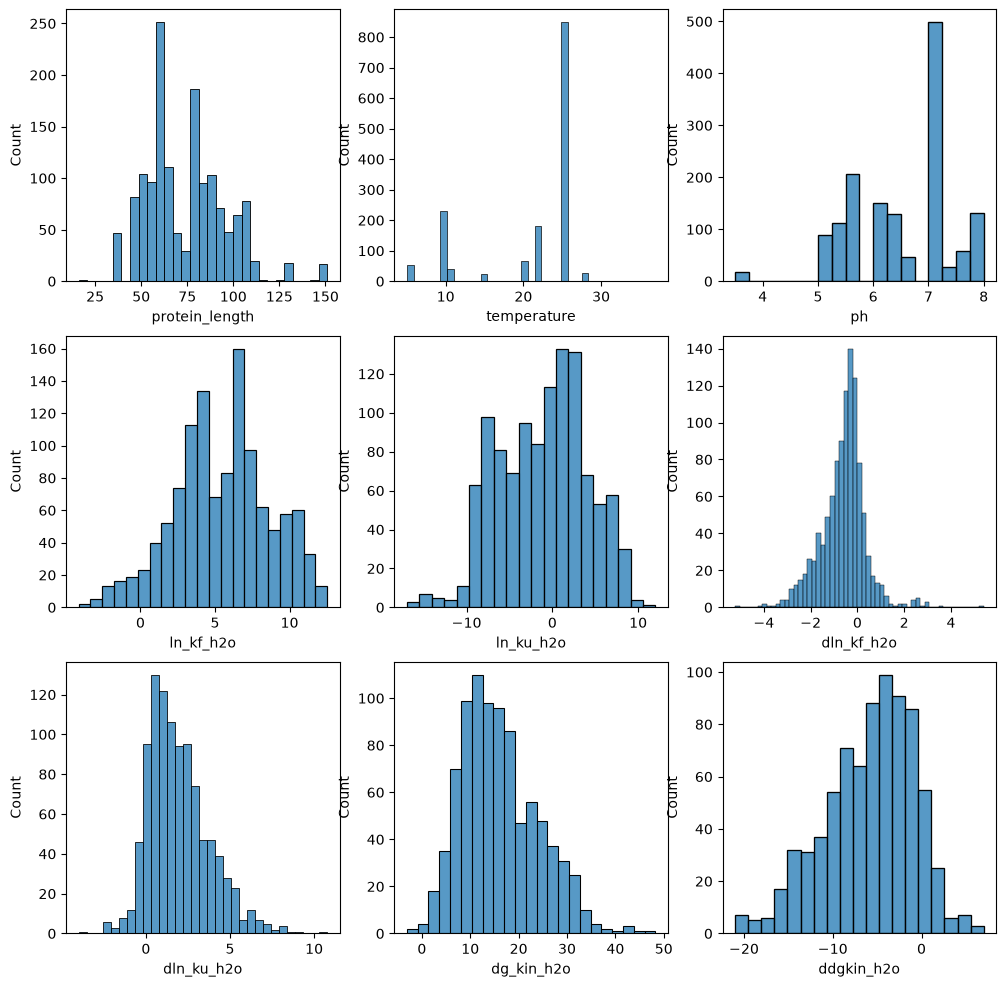

In [ ]:
# Plot distribution of numeric columns
column_names = ['protein_length', 'temperature', 'ph', 'ln_kf_h2o', 'ln_ku_h2o', 'dln_kf_h2o', 'dln_ku_h2o', 'dg_kin_h2o', 'ddgkin_h2o']
data_numeric = data[column_names]

fig, axes = plt.subplots(3, 3, figsize = (12, 12))

for i, ax in enumerate(fig.axes):
    sns.histplot(data = data, x = column_names[i], ax = ax)
    #ax.set_title(column_names[i].title())
plt.show()

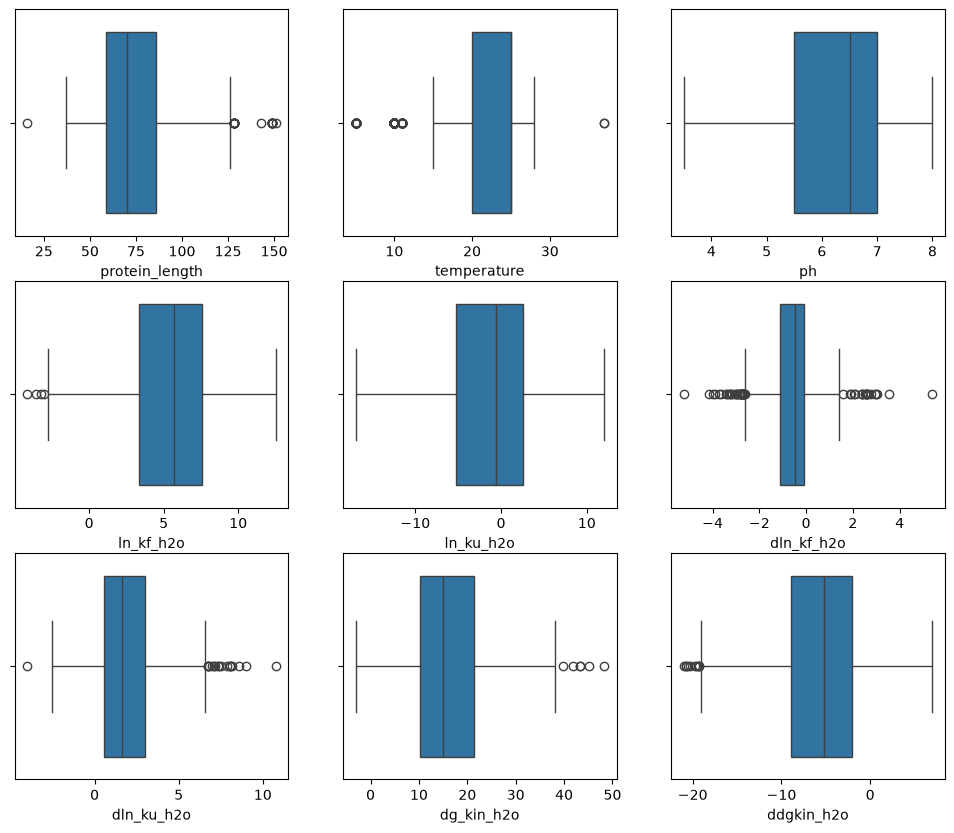

In [ ]:
fig, axes = plt.subplots(3, 3, figsize = (12, 10))

for i, ax in enumerate(fig.axes):
    sns.boxplot(data = data, x = column_names[i], ax = ax)
    #ax.set_title(column_names[i].title())
plt.show()

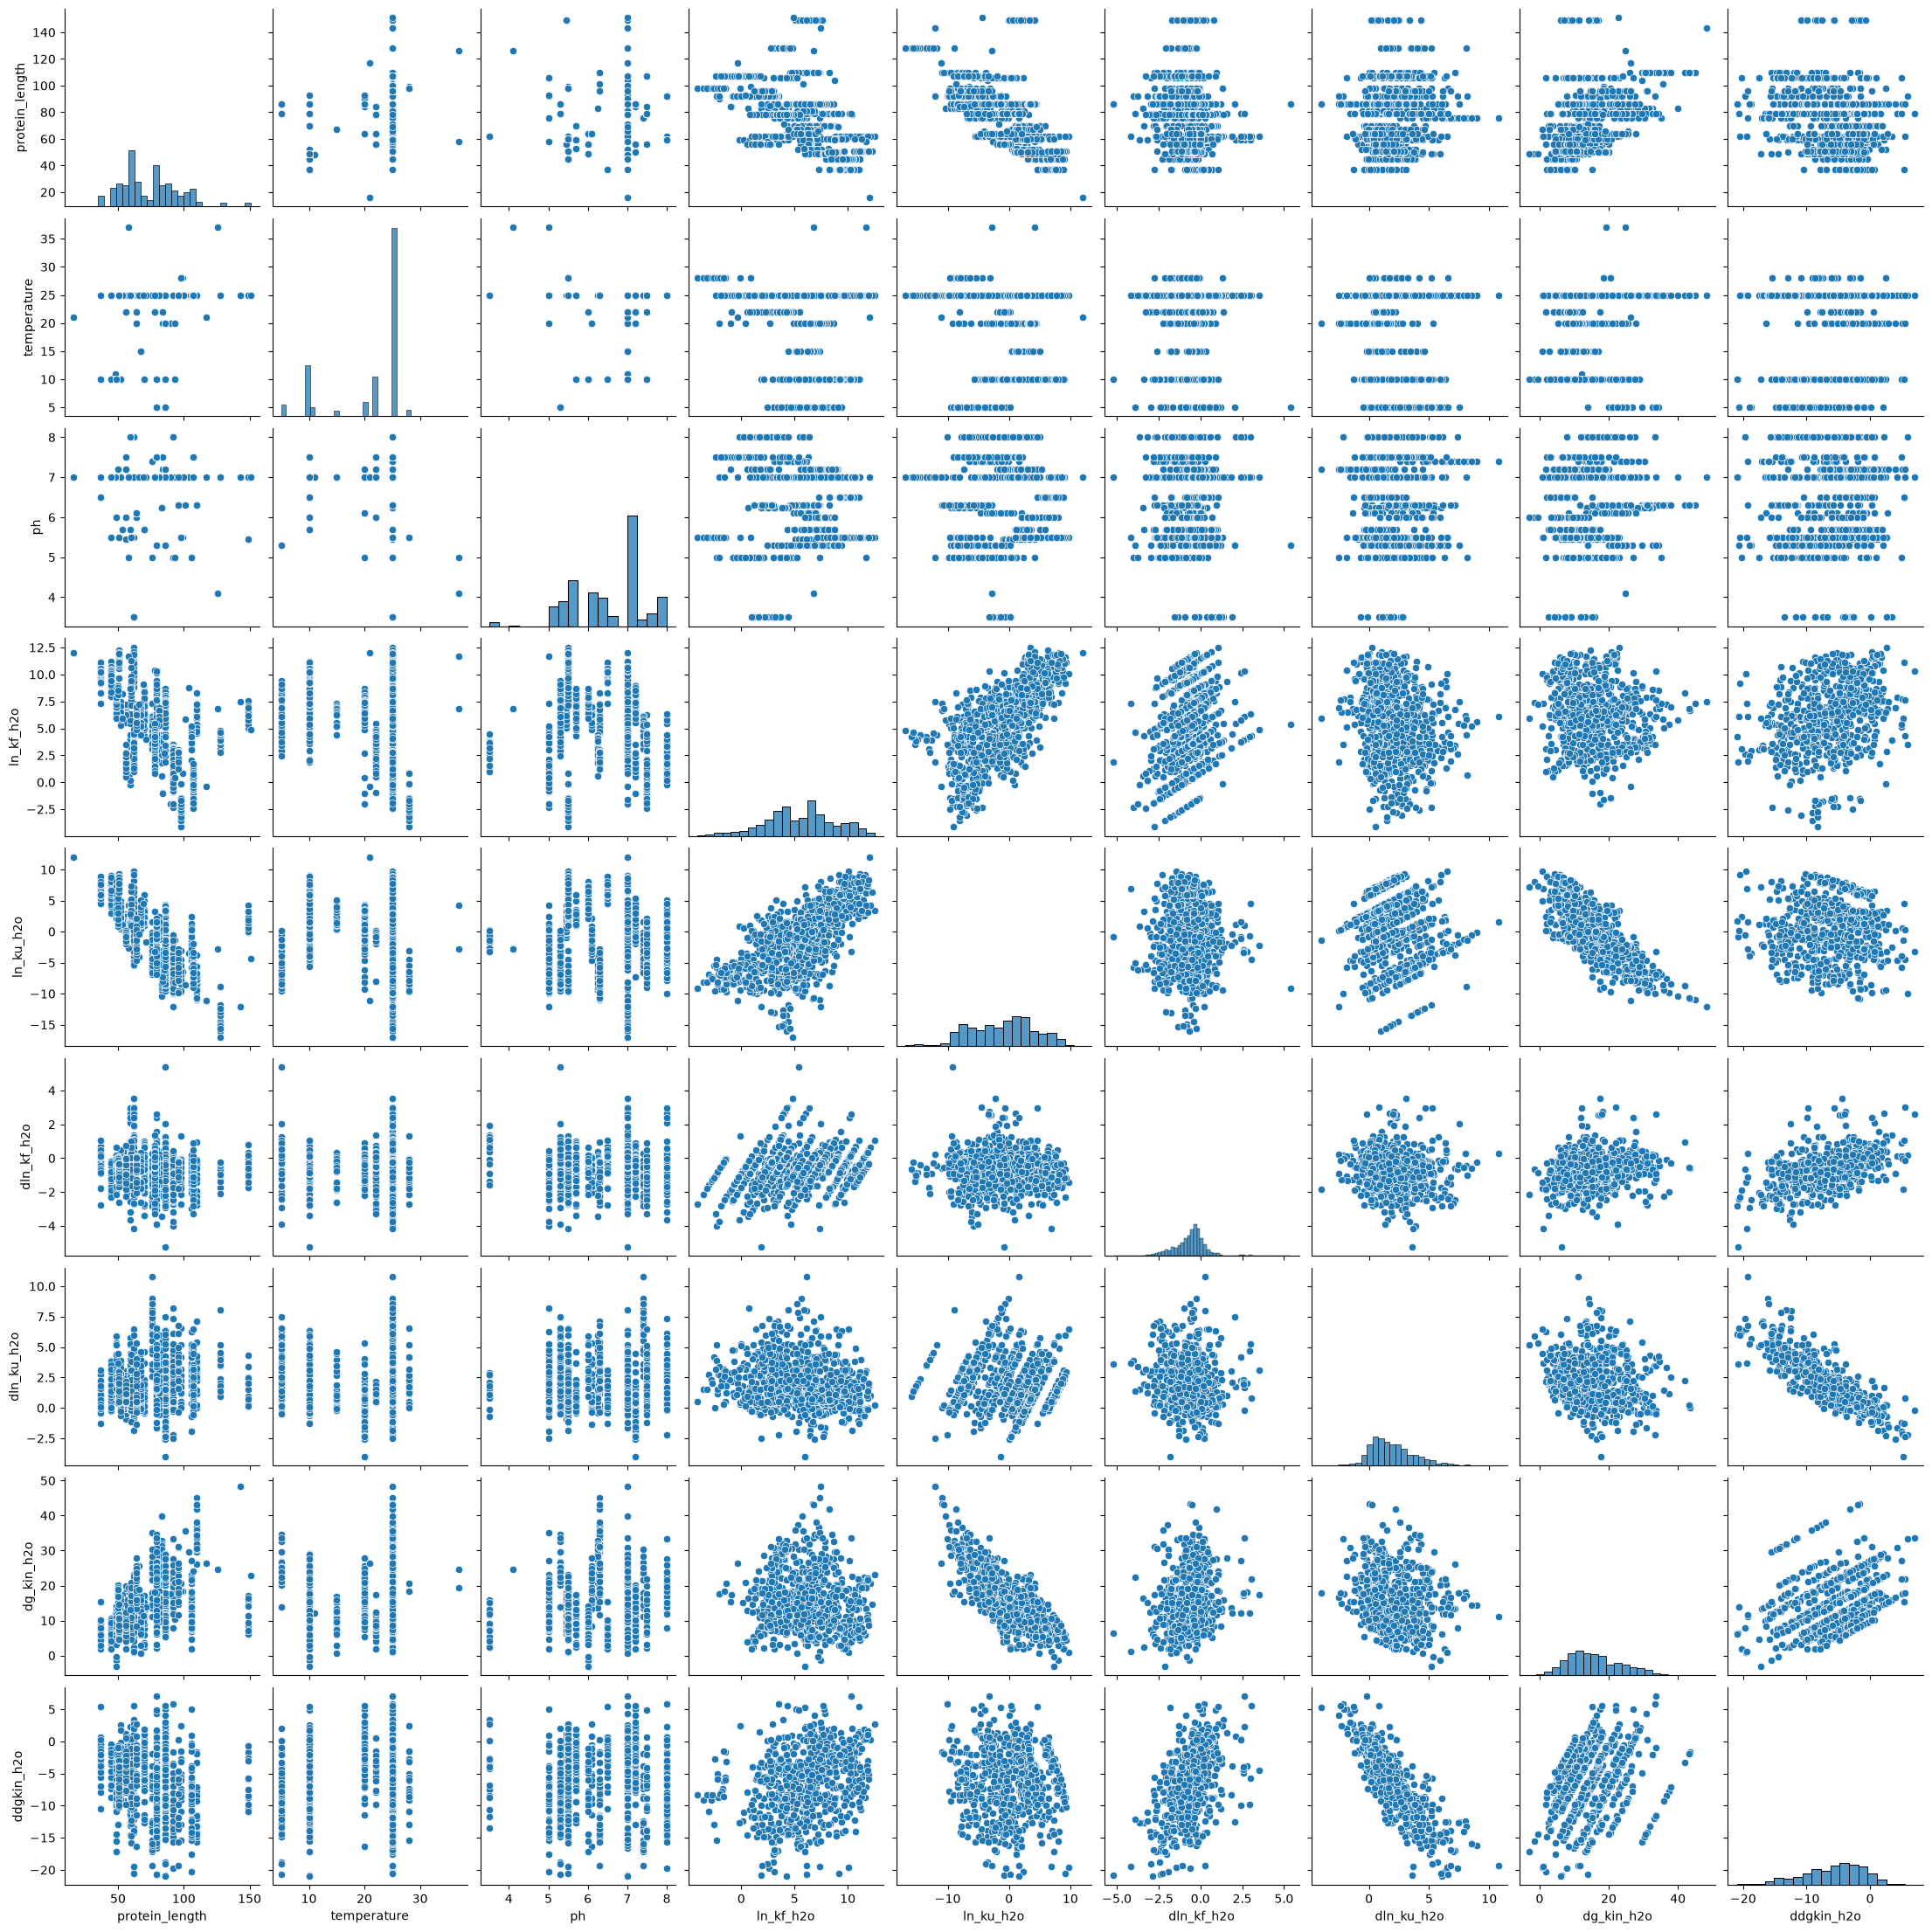

In [ ]:
# Explore correlations
sns.pairplot(data = data_numeric, vars = column_names)
plt.show()

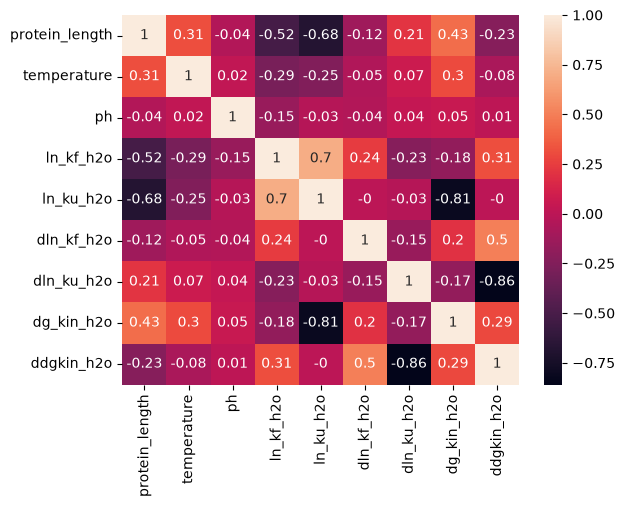

In [ ]:
plt.Figure(figsize = (10,6))
sns.heatmap(round(data_numeric.corr(), 2), annot=True)
plt.show()

### Summary
